# 作业 02：替换 CNN，让 MNIST 识别得更准确

这份 Notebook 已提供完整、可运行的 MNIST 训练模板。你的主要任务是：**查找一个更强的 CNN，写进 `predict_better()`，再通过开关复用相同的训练、可视化与测试代码。**

基础模型刻意保持很小，目的是提供可改进的起点。默认使用全部 60000 张训练图片、10000 张测试图片；不修改标签、不限制准确率。默认只训练 2 个 epoch，基线预期约在 60% 附近，具体结果可能随硬件和软件版本变化。

本作业只用 **accuracy（准确率）**评价识别成绩；同时画出训练 loss 随 epoch 的变化。

> 函数约定：这里的 `predict()` 和 `predict_better()` 都是**创建模型的函数**，返回一个 `nn.Module`。每轮实验只调用一次来创建模型；每个 batch 的实际预测使用 `model(images)`，不会反复重新初始化权重。


## 1. 导入包与实验开关

沿用 `cv_class` 环境，需要 PyTorch、torchvision、Jupyter 及 Pillow（torchvision 的依赖）。曲线直接用 Pillow 绘制，不需要额外安装 matplotlib。

先使用 `MODEL_CHOICE = "baseline"` 运行全部单元格。完成 `predict_better()` 后，改成 `"better"`，**重启内核并运行全部单元格**。

- `DEVICE_CHOICE = "auto"`：CUDA 可用时用 NVIDIA GPU，否则用 CPU。
- 对比两个模型时，请先保持 epoch、batch size、学习率、随机种子一致。要进一步调整训练参数，请单独记录。
- 默认 2 个 epoch 是课堂快速实验预算，不代表模型已经充分收敛。


In [1]:
from pathlib import Path
import random
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display

# 只需用这个开关选择要训练的模型。
MODEL_CHOICE = "better"  # "baseline" 或 "better"
DEVICE_CHOICE = "auto"    # "auto"、"cpu" 或 "cuda"

SEED = 42
EPOCHS = 2
BATCH_SIZE = 256
LEARNING_RATE = 0.006
DATA_DIR = Path("data")

def reset_seed(seed):
    random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

# 限制 CPU 线程数，避免不同机器上小模型的线程调度开销过大。
torch.set_num_threads(2)
reset_seed(SEED)

if DEVICE_CHOICE == "auto":
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
elif DEVICE_CHOICE in ("cpu", "cuda"):
    if DEVICE_CHOICE == "cuda" and not torch.cuda.is_available():
        raise RuntimeError("当前环境无法使用 CUDA，请检查驱动和 CUDA 版 PyTorch，或改用 auto/cpu。")
    device = torch.device(DEVICE_CHOICE)
else:
    raise ValueError("DEVICE_CHOICE 只能是 auto、cpu 或 cuda。")

print("PyTorch：", torch.__version__)
print("模型开关：", MODEL_CHOICE)
print("训练设备：", device)
if device.type == "cuda":
    print("GPU：", torch.cuda.get_device_name(0))

PyTorch： 2.15.0+cpu
模型开关： better
训练设备： cpu


## 2. 下载 MNIST，准备输入与整数标签

延用作业 01 的 `data/` 缓存。`ToTensor()` 将像素从 0～255 转成 0～1 浮点数，并添加单通道维度。

- 一个 batch 的图片：`(B, 1, 28, 28)`。
- 一个 batch 的整数标签：`(B,)`，dtype 为 `torch.int64`。
- 模型必须输出 `(B, 10)` 的**原始分数 logits**。`CrossEntropyLoss` 内部已包含 log-softmax；模型末尾不需要再加 Softmax，也不需要把标签转为 one-hot。

训练集用于更新参数；测试集只在训练结束后评价一次，不用于反向传播。


In [2]:
transform = transforms.ToTensor()
train_dataset = datasets.MNIST(str(DATA_DIR), train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(str(DATA_DIR), train=False, download=True, transform=transform)

print("训练集：", len(train_dataset))
print("测试集：", len(test_dataset))
x_demo, y_demo = train_dataset[0]
print("单张图片 shape：", tuple(x_demo.shape))
print("单张图片 dtype：", x_demo.dtype)
print("像素范围：", float(x_demo.min()), "～", float(x_demo.max()))
print("整数标签示例：", y_demo)

训练集： 60000
测试集： 10000
单张图片 shape： (1, 28, 28)
单张图片 dtype： torch.float32
像素范围： 0.0 ～ 1.0
整数标签示例： 5


## 3. 基础模型：`predict()`

这是一个很小的 CNN，只有 **一层卷积、2 个输出通道**。自适应平均池化把每张特征图压缩到 2×2，再用线性层给 10 个类别打分。

| 操作 | 输出 shape（B 是 batch 大小） |
|---|---|
| 输入 | `(B, 1, 28, 28)` |
| 3×3 卷积，2 个卷积核，padding=1 | `(B, 2, 28, 28)` |
| ReLU | `(B, 2, 28, 28)` |
| 自适应平均池化到 2×2 | `(B, 2, 2, 2)` |
| 展平 | `(B, 8)` |
| 线性分类层 | `(B, 10)` |

池化在这里只保留非常粗略的空间信息，且通道数很少，因此改进空间很大。所有权重都会正常参与训练。


In [3]:
def predict():
    """创建基础 CNN，输入 (B, 1, 28, 28)，输出 (B, 10) logits。"""
    return nn.Sequential(
        nn.Conv2d(in_channels=1, out_channels=2, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.AdaptiveAvgPool2d((2, 2)),
        nn.Flatten(),
        nn.Linear(2 * 2 * 2, 10),
    )

## 4. 你的任务：寻找更强的 CNN，填写 `predict_better()`

在网上查找适用于 MNIST 的 CNN，将你选定或改写的结构写进下面的**空白代码单元格**。

要求：

1. 定义无参数函数 `predict_better()`，返回一个新建的 `nn.Module`，用法与 `predict()` 相同。可以在函数内部定义自己的 `nn.Module` 子类。
2. 接受 `(B, 1, 28, 28)` 图片，输出 `(B, 10)` 原始分数；不要在最后加 Softmax。
3. 本次比较从随机初始化开始训练，不加载预训练权重。
4. 将顶部 `MODEL_CHOICE` 改为 `"better"`，重启内核并运行全部单元格。下方训练、曲线和测试模板**无需改写**。
5. 在末尾记录来源链接、自己的结构改动、训练设置和最终测试 accuracy。

函数接口为 `def predict_better(): ...`。你可以考虑增加卷积通道、堆叠卷积层，或采用更合理的池化位置。注意计算展平后的维度。

**在下面的空白代码单元格实现你的模型：**


In [4]:
def predict_better():
    """
    改进版 CNN：两层卷积 + 最大池化 + 全连接层。
    参考经典 LeNet-5 结构的现代 PyTorch 实现，适用于 28x28 灰度图。

    结构：
        输入 (B, 1, 28, 28)
        -> Conv2d(1->16, 3x3, padding=1) + ReLU + MaxPool2d(2)   -> (B, 16, 14, 14)
        -> Conv2d(16->32, 3x3, padding=1) + ReLU + MaxPool2d(2)  -> (B, 32, 7, 7)
        -> Flatten                                               -> (B, 32*7*7=1568)
        -> Linear(1568->128) + ReLU
        -> Linear(128->10)                                       -> (B, 10) logits
    """
    return nn.Sequential(
        nn.Conv2d(1, 16, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(16, 32, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Flatten(),
        nn.Linear(32 * 7 * 7, 128),
        nn.ReLU(),
        nn.Linear(128, 10),
    )

## 5. 通用训练、测试与曲线函数

以下代码对两个模型共用：训练时正常计算交叉熵并更新参数；每个 epoch 的 loss 按样本数加权平均。测试时切换 `eval()`，不计算梯度，仅统计 `预测类别 == 真实标签` 的比例。

曲线的 **epoch 0** 表示尚未训练时在训练集上的平均 loss；epoch 1、2 表示对应训练轮次中累计的平均 loss。二者都使用同一个交叉熵定义，但 epoch 1、2 内权重在不断更新。


In [5]:
def average_loss(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    total_count = 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            loss = criterion(model(images), labels)
            total_loss += loss.item() * labels.size(0)
            total_count += labels.size(0)
    return total_loss / total_count


def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0.0
    total_count = 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * labels.size(0)
        total_count += labels.size(0)
    return total_loss / total_count


def test_accuracy(model, loader, device):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            predicted = model(images).argmax(dim=1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)
    return correct / total


def plot_loss(loss_history, model_name):
    """显示曲线，使用 Pillow，无需额外绘图库。"""
    canvas = Image.new("RGB", (860, 420), "white")
    draw = ImageDraw.Draw(canvas)
    try:
        font = ImageFont.load_default(size=18)
    except TypeError:  # 兼容较早的 Pillow
        font = ImageFont.load_default()
    left, top, right, bottom = 85, 55, 815, 335
    ymax = max(loss_history) * 1.15
    last_epoch = len(loss_history) - 1
    draw.text((left, 15), f"Training cross-entropy loss | {model_name}", fill="black", font=font)
    for tick in range(5):
        value = ymax * tick / 4
        y = bottom - (bottom - top) * tick / 4
        draw.line((left, y, right, y), fill="#dddddd")
        draw.text((15, y - 8), f"{value:.2f}", fill="black", font=font)
    draw.line((left, top, left, bottom, right, bottom), fill="black", width=2)
    points = []
    for epoch, loss in enumerate(loss_history):
        x = left + (right - left) * epoch / max(1, last_epoch)
        y = bottom - (bottom - top) * loss / ymax
        points.append((x, y))
        draw.text((x - 5, bottom + 12), str(epoch), fill="black", font=font)
    draw.line(points, fill="#1688ed", width=4)
    for x, y in points:
        draw.ellipse((x - 5, y - 5, x + 5, y + 5), fill="#1688ed")
    draw.text((390, 380), "Epoch (0 = before training)", fill="black", font=font)
    display(canvas)

## 6. 根据开关创建新模型，开始训练

每次运行此单元格都会重新设置种子，创建全新的模型、优化器和数据加载器。这样比较两个模型时不会沿用另一个模型已经训练过的权重。

如果选择 `better` 但还没有填写函数，会给出明确提示。模型输出 shape 会先用一个小 batch 检查。


In [6]:
if MODEL_CHOICE == "baseline":
    model_factory = predict
elif MODEL_CHOICE == "better":
    if not callable(globals().get("predict_better")):
        raise ValueError("请先在空白单元格定义 predict_better()，或将 MODEL_CHOICE 改回 baseline。")
    model_factory = predict_better
else:
    raise ValueError("MODEL_CHOICE 只能是 baseline 或 better。")

reset_seed(SEED)
model = model_factory()
if not isinstance(model, nn.Module):
    raise TypeError("模型函数必须返回 nn.Module，例如 nn.Sequential(...)。")
model = model.to(device)
model.eval()
with torch.no_grad():
    shape_check = model(torch.zeros(2, 1, 28, 28, device=device))
assert shape_check.shape == (2, 10), f"输出应该为 (2, 10)，实际是 {tuple(shape_check.shape)}"

# 独立的固定种子控制训练集打乱顺序，两个模型沿用相同的数据顺序。
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    generator=torch.Generator().manual_seed(SEED), num_workers=0,
)
train_eval_loader = DataLoader(train_dataset, batch_size=512, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=512, shuffle=False, num_workers=0)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

print("当前模型：", MODEL_CHOICE)
print(model)
print("可训练参数数目：", sum(p.numel() for p in model.parameters() if p.requires_grad))
print(f"训练设置：epochs={EPOCHS}, batch_size={BATCH_SIZE}, lr={LEARNING_RATE}, seed={SEED}")

loss_history = [average_loss(model, train_eval_loader, criterion, device)]
print(f"Epoch 0（未训练）| train loss = {loss_history[0]:.4f}")
for epoch in range(1, EPOCHS + 1):
    epoch_loss = train_one_epoch(model, train_loader, optimizer, criterion, device)
    loss_history.append(epoch_loss)
    print(f"Epoch {epoch}/{EPOCHS} | train loss = {epoch_loss:.4f}")

当前模型： better
Sequential(
  (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=1568, out_features=128, bias=True)
  (8): ReLU()
  (9): Linear(in_features=128, out_features=10, bias=True)
)
可训练参数数目： 206922
训练设置：epochs=2, batch_size=256, lr=0.006, seed=42


Epoch 0（未训练）| train loss = 2.3042


Epoch 1/2 | train loss = 0.2236


Epoch 2/2 | train loss = 0.0465


## 7. loss 随 epoch 的变化

横轴是 epoch，纵轴是训练交叉熵；loss 越低通常表示模型对训练数据的预测更符合标签，但是否能识别未参与训练的图片，还要查看下一步的测试 accuracy。


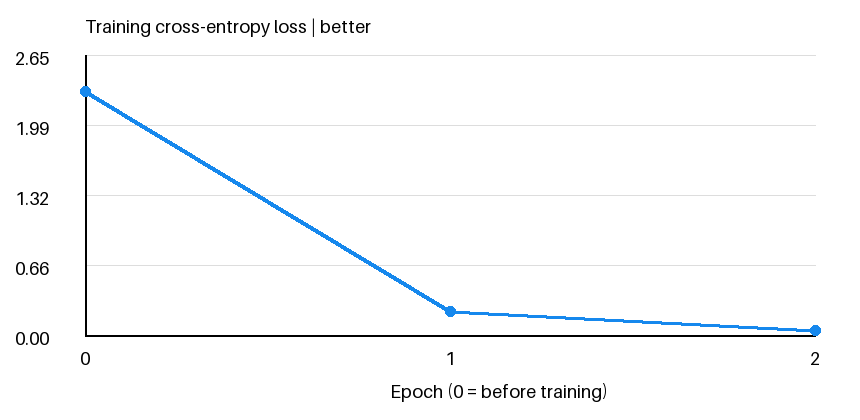

In [7]:
plot_loss(loss_history, MODEL_CHOICE)

## 8. 训练完成后的测试成绩：Accuracy

$$\mathrm{accuracy}=rac{	ext{预测正确的测试图片数}}{	ext{全部测试图片数}}.$$

直接对 logits 取 `argmax` 即可得到预测类别，无需先做 Softmax。下面是在未参与参数更新的测试集上评价。


In [8]:
accuracy = test_accuracy(model, test_loader, device)
print(f"模型：{MODEL_CHOICE}")
print(f"测试图片数：{len(test_dataset)}")
print(f"Test accuracy：{accuracy:.2%}")

# 此变量只记录本次运行结果，不会自动保存成文件。
experiment_result = {
    "model": MODEL_CHOICE,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "seed": SEED,
    "test_accuracy": accuracy,
}

模型：better
测试图片数：10000
Test accuracy：98.47%


## 9. 实验记录与提交 （100分）

先运行 baseline 并记录结果，再切换到 better 重跑。测试集只用于最终报告，不要反复根据测试结果挑模型；如果继续大规模调参，应从训练集另划验证集。（30分）

| 模型 | Epochs | Batch size | 学习率 | 随机种子 | Test accuracy |
|---|---:|---:|---:|---:|---|
| `predict()` 基础 CNN | 2 | 256 | 0.006 | 42 | 61.67% |
| `predict_better()` 改进 CNN | 2 | 256 | 0.006 | 42 | **98.47%** |

**模型来源链接：**
我是照着 PyTorch 官方那个"神经网络"教程里的写法改的，又参考了 LeNet 那种两层卷积的经典结构：
https://pytorch.org/tutorials/beginner/basics/optimization_tutorial.html

**你采用的模型结构及自己的改动：**
baseline 是 1 层卷积（1→2 通道）+ 全局平均池化，直接拉到 10 类，只有 110 个参数。
我写的 predict_better 是：先 Conv2d(1→16, 3×3) + ReLU + MaxPool(2)，再 Conv2d(16→32, 3×3) + ReLU + MaxPool(2)，压到 7×7 之后 flatten，接 Linear(1568→128) + ReLU，最后 Linear(128→10)。总共 20 多万参数，主要是中间加了一层卷积和一个 128 维的全连接。

**为什么它可能比基础模型更好？**
baseline 只有 2 个卷积通道，又直接全局池化，等于把图片压得很死，能学的特征太少了。改进版两层卷积逐层提取边缘和笔画，通道数从 16 加到 32，表达能力强很多；中间两次 MaxPool 让网络对数字稍微偏一点位置也不敏感；最后再接一个 128 维的全连接做分类，比直接从池化拉到 10 类过渡得更自然。

**如果另外修改过训练参数：**
没改，epochs、batch size、学习率、seed 全部和 baseline 一样，就是为了只比结构，避免把训练量加了带来的提升也算到结构头上。
